# 01 — NIR data exploration

## Goal

Understand the supplied spectra table, check its metadata and split structure, and make a reproducible **replicate-grouped** train/test partition for later modeling. This notebook is descriptive: it does not fit a classifier or claim performance.

## Split decision

`Img_ID` identifies an image and its suffix (`R1`, `R2`, or `R3`) agrees with the `Replicate` column. IDs sharing the prefix before that suffix are treated as replicate images of one family. Spectra from one family must not cross train and test, because those measurements may share sample-specific signal. This is a conservative grouping assumption inferred from the documented replicate field and observed ID format; confirm it with the dataset owner before making deployment claims.

The original `TR/TS` labels remain unchanged for audit. A separate four-fold stratified group partition is added below (seed 42, fold 0). This changes the provided holdout because four adulterant replicate families are split between its original train and test partitions. Grouping them into one side reduces the risk of evaluating on near-replicate images already represented in training. The chosen fold is fixed in advance; do not select a different fold based on model results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from nir_adulterants_detection.data import (
    SPECTRAL_COLUMNS,
    WAVELENGTHS_NM,
    load_spectra_csv,
)
from nir_adulterants_detection.splitting import (
    GROUPED_PARTITION_COLUMN,
    REPLICATE_GROUP_COLUMN,
    add_grouped_partition,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Oregano_NIR.csv"

spectra = load_spectra_csv(DATA_PATH)
print(f"Loaded and validated: {DATA_PATH}")

Loaded and validated: /home/irasionize/ML Projects/NIR-adulterants-detection/data/raw/Oregano_NIR.csv


## 1. Dataset dimensions and data quality

The loader checks the semicolon-delimited schema, metadata values, and finite numeric reflectance values. This section summarizes what passed those checks.

In [2]:
quality_summary = pd.Series(
    {
        "spectra rows": len(spectra),
        "columns": spectra.shape[1],
        "metadata columns": len(spectra.columns) - len(SPECTRAL_COLUMNS),
        "wavelength columns": len(SPECTRAL_COLUMNS),
        "unique images": spectra["Img_ID"].nunique(),
        "missing cells": int(spectra.isna().sum().sum()),
        "all reflectance values finite": bool(
            np.isfinite(spectra[list(SPECTRAL_COLUMNS)].to_numpy(dtype=float)).all()
        ),
        "first wavelength (nm)": WAVELENGTHS_NM[0],
        "last wavelength (nm)": WAVELENGTHS_NM[-1],
    },
    name="Value",
)
display(quality_summary.to_frame())

print("Rows per image:")
display(
    spectra.groupby("Img_ID", observed=True)
    .size()
    .describe()
    .to_frame("spectra per image")
)

,Value
spectra rows,14400
columns,142
metadata columns,5
wavelength columns,137
unique images,84
missing cells,0
all reflectance values finite,True
first wavelength (nm),980
last wavelength (nm),1660


Rows per image:


,spectra per image
count,84.000000
mean,171.428571
std,176.014395
min,100.000000
25%,100.000000
50%,100.000000
75%,100.000000
max,600.000000


## 2. Labels, materials, and provided partition

`Class` is the binary prediction target (`Ad` or `Or`). `Info` records material type. Row counts alone can hide the number of independent images or replicate families, so the tables report all three units.

In [3]:
display(
    pd.crosstab(spectra["Info"], spectra["Class"], margins=True).rename_axis("Info")
)

original_grouped = add_grouped_partition(spectra)


def partition_summary(frame, partition_column):
    return (
        frame.groupby([partition_column, "Class"], observed=True)
        .agg(
            spectra_rows=("Img_ID", "size"),
            images=("Img_ID", "nunique"),
            replicate_families=(REPLICATE_GROUP_COLUMN, "nunique"),
        )
        .rename_axis(index=["partition", "Class"])
    )


print("Counts under the supplied TR/TS labels:")
display(partition_summary(original_grouped, "TR/TS"))

Class,Ad,Or,All
Info,,,
Myrtle,1800,0,1800
Olive,1800,0,1800
Oregano,0,6900,6900
Oregano (infl.),0,300,300
Strawberry tree,1800,0,1800
Sumac,1800,0,1800
All,7200,7200,14400


Counts under the supplied TR/TS labels:


spectra_rows  images  replicate_families
partition Class                                          
TR        Ad             4800       8                   4
          Or             4800      48                  16
TS        Ad             2400       4                   4
          Or             2400      24                   8

## 3. Audit replicate-family overlap

The original labels keep exact `Img_ID` values separate, but that is not sufficient if the three replicate images share a family prefix. The following audit counts families represented in both original partitions.

In [4]:
original_family_partitions = pd.crosstab(
    original_grouped[REPLICATE_GROUP_COLUMN], original_grouped["TR/TS"]
)
original_mixed_families = original_family_partitions.index[
    original_family_partitions.gt(0).sum(axis=1) > 1
]
print(f"Replicate families crossing original TR/TS: {len(original_mixed_families)}")
display(
    original_family_partitions.loc[original_mixed_families].rename_axis(
        "replicate family"
    )
)

replicate_suffix_audit = original_grouped.groupby(
    REPLICATE_GROUP_COLUMN, observed=True
).agg(
    image_count=("Img_ID", "nunique"),
    replicate_count=("Replicate", "nunique"),
    classes=("Class", "nunique"),
)
display(replicate_suffix_audit.describe().T)

Replicate families crossing original TR/TS: 4


TR/TS,TR,TS
replicate family,,
P_A_05,1200,600
P_A_06,1200,600
P_A_07,1200,600
P_A_08,1200,600


,count,mean,std,min,25%,50%,75%,max
image_count,28.0,3.0,0.0,3.0,3.0,3.0,3.0,3.0
replicate_count,28.0,3.0,0.0,3.0,3.0,3.0,3.0,3.0
classes,28.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


## 4. Construct the grouped holdout

The splitter uses `Class` only to balance the folds and the derived replicate-family ID to keep related images together. The original `TR/TS` column is preserved; `Grouped_TR_TS` is the candidate partition for later model development.

In [5]:
grouped = add_grouped_partition(
    spectra,
    n_splits=4,
    test_fold=0,
    random_state=42,
)

train_groups = set(
    grouped.loc[grouped[GROUPED_PARTITION_COLUMN] == "TR", REPLICATE_GROUP_COLUMN]
)
test_groups = set(
    grouped.loc[grouped[GROUPED_PARTITION_COLUMN] == "TS", REPLICATE_GROUP_COLUMN]
)
train_images = set(grouped.loc[grouped[GROUPED_PARTITION_COLUMN] == "TR", "Img_ID"])
test_images = set(grouped.loc[grouped[GROUPED_PARTITION_COLUMN] == "TS", "Img_ID"])

assert train_groups.isdisjoint(test_groups)
assert train_images.isdisjoint(test_images)
assert set(grouped["Class"].unique()) == set(
    grouped.loc[grouped[GROUPED_PARTITION_COLUMN] == "TR", "Class"].unique()
)
assert set(grouped["Class"].unique()) == set(
    grouped.loc[grouped[GROUPED_PARTITION_COLUMN] == "TS", "Class"].unique()
)

print(f"Train replicate families: {len(train_groups)}")
print(f"Test replicate families: {len(test_groups)}")
print(f"Shared replicate families: {len(train_groups & test_groups)}")
print(f"Shared image IDs: {len(train_images & test_images)}")
display(partition_summary(grouped, GROUPED_PARTITION_COLUMN))

Train replicate families: 21
Test replicate families: 7
Shared replicate families: 0
Shared image IDs: 0


spectra_rows  images  replicate_families
partition Class                                          
TR        Ad             5400       9                   3
          Or             5400      54                  18
TS        Ad             1800       3                   1
          Or             1800      18                   6

spectra_rows  images  replicate_families
split design   partition Class                                          
Provided split TR        Ad             4800       8                   4
                         Or             4800      48                  16
               TS        Ad             2400       4                   4
                         Or             2400      24                   8
Grouped split  TR        Ad             5400       9                   3
                         Or             5400      54                  18
               TS        Ad             1800       3                   1
                         Or             1800      18                   6

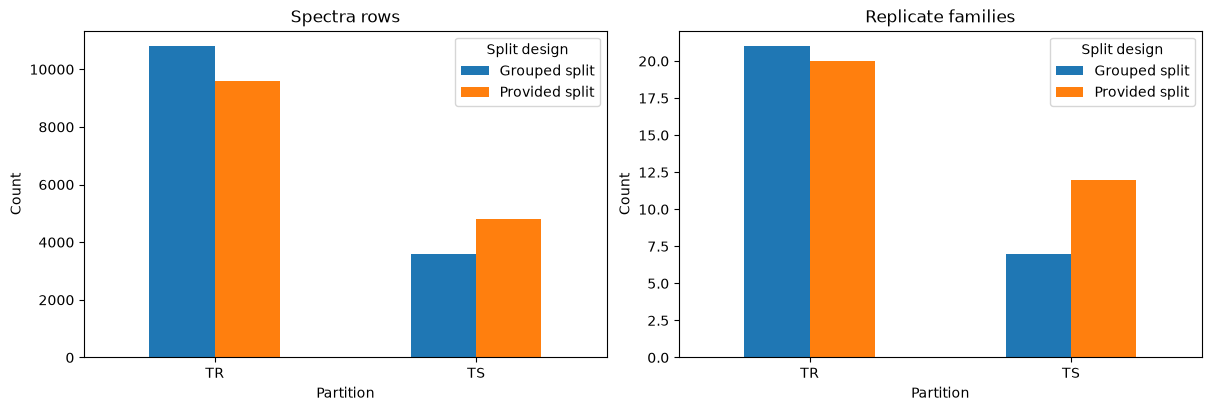

In [6]:
comparison = pd.concat(
    {
        "Provided split": partition_summary(original_grouped, "TR/TS"),
        "Grouped split": partition_summary(grouped, GROUPED_PARTITION_COLUMN),
    },
    names=["split design", "partition", "Class"],
)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, metric, title in zip(
    axes,
    ["spectra_rows", "replicate_families"],
    ["Spectra rows", "Replicate families"],
    strict=True,
):
    summary = comparison.reset_index()
    summary = (
        summary.groupby(["split design", "partition"], observed=True)[metric]
        .sum()
        .unstack(0)
    )
    summary.plot(kind="bar", ax=ax, rot=0)
    ax.set_title(title)
    ax.set_xlabel("Partition")
    ax.set_ylabel("Count")
    ax.legend(title="Split design")
plt.show()

## 5. Training-only reflectance overview

For this plot, spectra are first averaged within each image and then averaged across images within each replicate family. Each training family therefore contributes one spectrum to its class summary, regardless of the number of pixel spectra in that image. Shading shows one standard deviation across families; this is descriptive, and the adulterant estimate has few independent families.

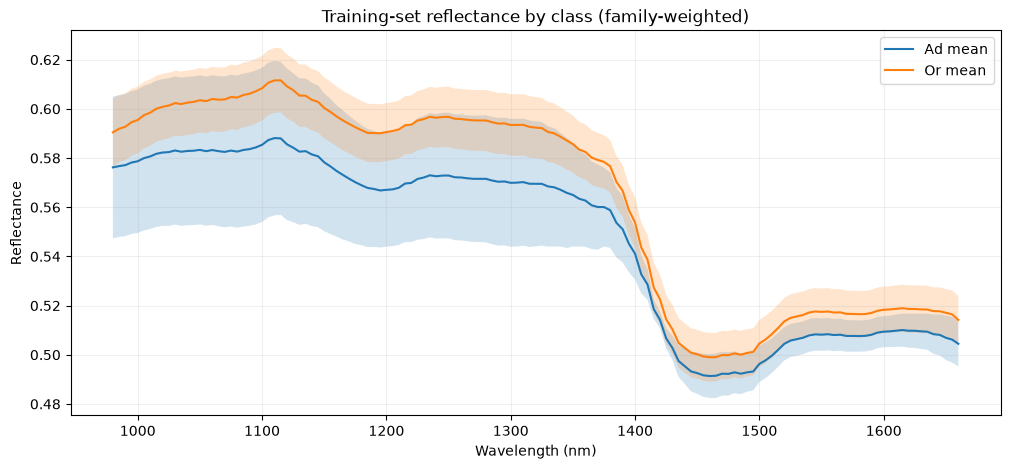

Independent training families per class:


,replicate families
Class,
Ad,3
Or,18


In [7]:
train = grouped.loc[grouped[GROUPED_PARTITION_COLUMN] == "TR"]
image_spectra = train.groupby(
    [REPLICATE_GROUP_COLUMN, "Img_ID", "Class"], observed=True
)[list(SPECTRAL_COLUMNS)].mean()
family_spectra = image_spectra.groupby(level=[REPLICATE_GROUP_COLUMN, "Class"]).mean()

fig, ax = plt.subplots(figsize=(12, 5))
for class_label in sorted(family_spectra.index.get_level_values("Class").unique()):
    class_values = family_spectra.xs(class_label, level="Class").to_numpy(dtype=float)
    mean_spectrum = class_values.mean(axis=0)
    std_spectrum = class_values.std(axis=0, ddof=1)
    ax.plot(WAVELENGTHS_NM, mean_spectrum, label=f"{class_label} mean")
    ax.fill_between(
        WAVELENGTHS_NM,
        mean_spectrum - std_spectrum,
        mean_spectrum + std_spectrum,
        alpha=0.2,
    )
ax.set(
    title="Training-set reflectance by class (family-weighted)",
    xlabel="Wavelength (nm)",
    ylabel="Reflectance",
)
ax.legend()
ax.grid(alpha=0.2)
plt.show()

print("Independent training families per class:")
display(
    family_spectra.groupby(level="Class").size().rename("replicate families").to_frame()
)

## Findings and limits

- The notebook uses the original CSV as read-only input. The grouped partition is an in-memory derived split; it does not rewrite the dataset.
- The provided split has replicate-family overlap. The new partition keeps all observed replicate images from a family on one side and maintains both classes in the selected fold.
- The group key is inferred from the image-ID naming convention and checked against `Replicate`. Confirm that the shared prefix means the same underlying physical sample in the experimental protocol.
- There are only four adulterant replicate families. A four-fold holdout leaves three such families for training and one for testing. Metrics from this small test set will have substantial uncertainty.
- This binary classification task distinguishes the supplied `Ad` and `Or` labels. It does not establish adulterant identity, concentration, or performance on new instruments, origins, or acquisition conditions.
- The reflectance summary is exploratory and uses training data only. Any later preprocessing, feature selection, and hyperparameter tuning must be fit within training data and use group-aware validation.